# Step 2: Municipality data, integration and assignment of the restaurants

This notebook
- loads the Swiss municipality boundaries (swissBOUNDARIES3D, as of January 2026) including the population per municipality,
- compares the set of municipalities with the BFS municipality directory,
- assigns every restaurant to a municipality with a **spatial join** (point in municipality),
- computes the number of vegan restaurants and the density per 1000 inhabitants for each municipality,
- stores everything in SQLite (tables `municipalities`, `restaurants`, `integration_log`) and shows a first map.

Every integration step is logged with the number of records (required by the assignment: key matching, joins, records lost/gained).

Prerequisite: Notebook 01 has been run (`data/processed/vegan_restaurants_ch.csv` exists).

In [1]:
%pip install geopandas pyogrio matplotlib
import sqlite3
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

## Paths and integration log

In [2]:
BOUNDARIES_ZIP = '../data/raw/swissboundaries3d_2026-01_2056_5728.gdb.zip'
DIRECTORY_CSV = '../data/raw/bfs_municipality_directory.csv'
RESTAURANTS_CSV = '../data/processed/vegan_restaurants_ch.csv'
DB_PATH = '../data/processed/vegan_project.db'

integration_log = []

def log(step, description, n_records):
    integration_log.append({'step': step, 'description': description, 'n_records': int(n_records)})
    print(f'[{step}] {description}: {int(n_records)}')

## 1. Load municipality boundaries (swisstopo, swissBOUNDARIES3D)

Besides the political municipalities, the layer `TLM_HOHEITSGEBIET` also contains lakes (`OBJEKTART = 1`), unincorporated areas (`OBJEKTART = 2`) and territories of Liechtenstein, Germany (Büsingen) and Italy (Campione). For the analysis we only keep the **municipal territories of Switzerland** (`ICC = CH`, `OBJEKTART = 0`).
The file also contains the population (`EINWOHNERZAHL`), which we use as the denominator for the density per 1000 inhabitants.

In [3]:
raw = gpd.read_file(BOUNDARIES_ZIP, layer='TLM_HOHEITSGEBIET')
log('1', 'Territories in swissBOUNDARIES3D (raw)', len(raw))

muni = raw[(raw['ICC'] == 'CH') & (raw['OBJEKTART'] == 0)].copy()
log('1', 'of which municipal territories of Switzerland (ICC = CH, OBJEKTART = 0)', len(muni))

# Reduce 3D geometry to 2D, set the coordinate system LV95 (EPSG:2056)
muni['geometry'] = muni.geometry.force_2d()
muni = muni.set_crs(2056, allow_override=True)

muni = muni[['BFS_NUMMER', 'NAME', 'KANTONSNUMMER', 'BEZIRKSNUMMER', 'GEM_FLAECHE', 'EINWOHNERZAHL', 'geometry']].rename(columns={
    'BFS_NUMMER': 'bfs_number', 'NAME': 'name', 'KANTONSNUMMER': 'canton_nr', 'BEZIRKSNUMMER': 'district_nr',
    'GEM_FLAECHE': 'area_ha', 'EINWOHNERZAHL': 'population'})
muni['bfs_number'] = muni['bfs_number'].astype(int)

print('Total population:', int(muni['population'].sum()))
print('Municipalities without inhabitants:', int((muni['population'] == 0).sum()))
muni.head()

[1] Territories in swissBOUNDARIES3D (raw): 2136
[1] of which municipal territories of Switzerland (ICC = CH, OBJEKTART = 0): 2110
Total population: 9051029
Municipalities without inhabitants: 0


,bfs_number,name,canton_nr,district_nr,area_ha,population,geometry
0,131,Adliswil,1.0,106.0,777,19893,"MULTIPOLYGON (((2682588.433 1239418.954, 26825..."
1,3714,Rheinwald,18.0,1851.0,13681,570,"MULTIPOLYGON (((2747636.177 1152720.387, 27476..."
2,5722,Grens,22.0,2228.0,256,391,"MULTIPOLYGON (((2505186.356 1139817.844, 25051..."
3,6730,Val Terbi,26.0,2601.0,4669,3270,"MULTIPOLYGON (((2602713.788 1239572.35, 260270..."
4,4123,Windisch,19.0,1904.0,491,8153,"MULTIPOLYGON (((2659073.266 1256864.692, 26590..."


## 2. Compare the set of municipalities with the BFS municipality directory

All sources must use the same set of municipalities (municipal mergers!). We check whether the BFS numbers of the boundary file exactly match the current municipalities in the directory (`Level = 3`, no `ValidTo`).

In [4]:
directory = pd.read_csv(DIRECTORY_CSV, dtype=str)
current = directory[(directory['Level'] == '3') & (directory['ValidTo'].isna())]
log('2', 'Current municipalities in the BFS municipality directory', len(current))

codes_boundaries = set(muni['bfs_number'])
codes_directory = set(current['BfsCode'].astype(int))
log('2', 'BFS numbers in boundary file but not in directory', len(codes_boundaries - codes_directory))
log('2', 'BFS numbers in directory but not in boundary file', len(codes_directory - codes_boundaries))

[2] Current municipalities in the BFS municipality directory: 2110
[2] BFS numbers in boundary file but not in directory: 0
[2] BFS numbers in directory but not in boundary file: 0


## 3. Load restaurants and assign municipalities (spatial join)

The restaurants have coordinates in WGS84 (EPSG:4326). They are converted to LV95 (EPSG:2056) and assigned with `within` to the municipality that contains the point. Place names from OSM (`city`) are deliberately not used because they are missing for more than a third of the entries.

In [5]:
r = pd.read_csv(RESTAURANTS_CSV, dtype={'postcode': str})
log('3', 'Restaurants from OpenStreetMap', len(r))

pts = gpd.GeoDataFrame(r, geometry=gpd.points_from_xy(r['lon'], r['lat']), crs='EPSG:4326').to_crs(2056)
joined = gpd.sjoin(pts, muni[['bfs_number', 'geometry']], how='left', predicate='within').drop(columns='index_right')

log('3', 'Restaurants assigned to a municipality', joined['bfs_number'].notna().sum())
log('3', 'Restaurants without municipality (e.g. in a lake or outside Switzerland)', joined['bfs_number'].isna().sum())
log('3', 'Restaurants assigned twice (check, should be 0)', joined.duplicated(['osm_type', 'osm_id']).sum())

[3] Restaurants from OpenStreetMap: 712
[3] Restaurants assigned to a municipality: 712
[3] Restaurants without municipality (e.g. in a lake or outside Switzerland): 0
[3] Restaurants assigned twice (check, should be 0): 0


## 4. Aggregate per municipality

With `how='left'`, municipalities without a restaurant are kept as well (count 0). Density = number of restaurants / population × 1000.

In [6]:
counts = joined.groupby('bfs_number').agg(
    n_restaurants=('osm_id', 'size'),
    n_vegan_only=('vegan_only', 'sum')).reset_index()

muni_stat = muni.merge(counts, on='bfs_number', how='left')
muni_stat[['n_restaurants', 'n_vegan_only']] = muni_stat[['n_restaurants', 'n_vegan_only']].fillna(0).astype(int)
muni_stat['density_per_1000'] = muni_stat['n_restaurants'] / muni_stat['population'] * 1000

log('4', 'Municipalities with at least one restaurant', (muni_stat['n_restaurants'] > 0).sum())
log('4', 'Municipalities without a restaurant', (muni_stat['n_restaurants'] == 0).sum())
log('4', 'Total restaurants in the municipality table (check)', muni_stat['n_restaurants'].sum())

[4] Municipalities with at least one restaurant: 158
[4] Municipalities without a restaurant: 1952
[4] Total restaurants in the municipality table (check): 712


## 5. Store in SQLite and query with SQL

The table `restaurants` is extended by the column `bfs_number` (it replaces the table from Notebook 01). The municipality table `municipalities` contains no geometry (it is stored in the GeoPackage file).

In [7]:
restaurants_tab = pd.DataFrame(joined.drop(columns='geometry'))
municipalities_tab = pd.DataFrame(muni_stat.drop(columns='geometry'))

with sqlite3.connect(DB_PATH) as conn:
    restaurants_tab.to_sql('restaurants', conn, if_exists='replace', index=False)
    municipalities_tab.to_sql('municipalities', conn, if_exists='replace', index=False)

    query = """
    SELECT m.bfs_number, m.name, m.population,
           COUNT(r.osm_id) AS n_restaurants,
           ROUND(1000.0 * COUNT(r.osm_id) / m.population, 3) AS density_per_1000
    FROM municipalities m
    LEFT JOIN restaurants r ON r.bfs_number = m.bfs_number
    GROUP BY m.bfs_number
    ORDER BY n_restaurants DESC
    LIMIT 10
    """
    top10 = pd.read_sql(query, conn)

    total_sql = pd.read_sql('SELECT COUNT(*) AS n FROM restaurants WHERE bfs_number IS NOT NULL', conn)['n'][0]

log('5', 'Restaurants with municipality in SQLite (check via SQL)', total_sql)
top10

[5] Restaurants with municipality in SQLite (check via SQL): 712


,bfs_number,name,population,n_restaurants,density_per_1000
0,261,Zürich,436551,190,0.435
1,351,Bern,137995,62,0.449
2,2701,Basel,177571,51,0.287
3,5586,Lausanne,144873,29,0.200
4,230,Winterthur,120376,27,0.224
5,1061,Luzern,86234,23,0.267
6,6621,Genève,209061,17,0.081
7,3203,St. Gallen,78863,13,0.165
8,5890,Vevey,20142,12,0.596
9,371,Biel/Bienne,56896,9,0.158


## 6. First overview

In [8]:
print('Municipalities in total:', len(muni_stat))
print('Share of municipalities without a restaurant: {:.1%}'.format((muni_stat['n_restaurants'] == 0).mean()))
print()
print('Distribution of the number of restaurants per municipality:')
print(muni_stat['n_restaurants'].describe())
print()
print('Top 10 by density (only municipalities with at least 2000 inhabitants):')
muni_stat[muni_stat['population'] >= 2000].nlargest(10, 'density_per_1000')[['name', 'population', 'n_restaurants', 'density_per_1000']]

Municipalities in total: 2110
Share of municipalities without a restaurant: 92.5%

Distribution of the number of restaurants per municipality:
count    2110.000000
mean        0.337441
std         4.666078
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       190.000000
Name: n_restaurants, dtype: float64

Top 10 by density (only municipalities with at least 2000 inhabitants):


,name,population,n_restaurants,density_per_1000
1684,Flims,2902,3,1.033770
1271,Grindelwald,3930,4,1.017812
1358,Zermatt,6099,5,0.819807
1153,Selzach,3690,3,0.813008
1828,Surses,2465,2,0.811359
1965,Wildhaus-Alt St. Johann,2601,2,0.768935
1198,Schwende-Rüte,6108,4,0.654879
178,Vevey,20142,12,0.595770
1626,Adelboden,3420,2,0.584795
2010,Interlaken,6123,3,0.489956


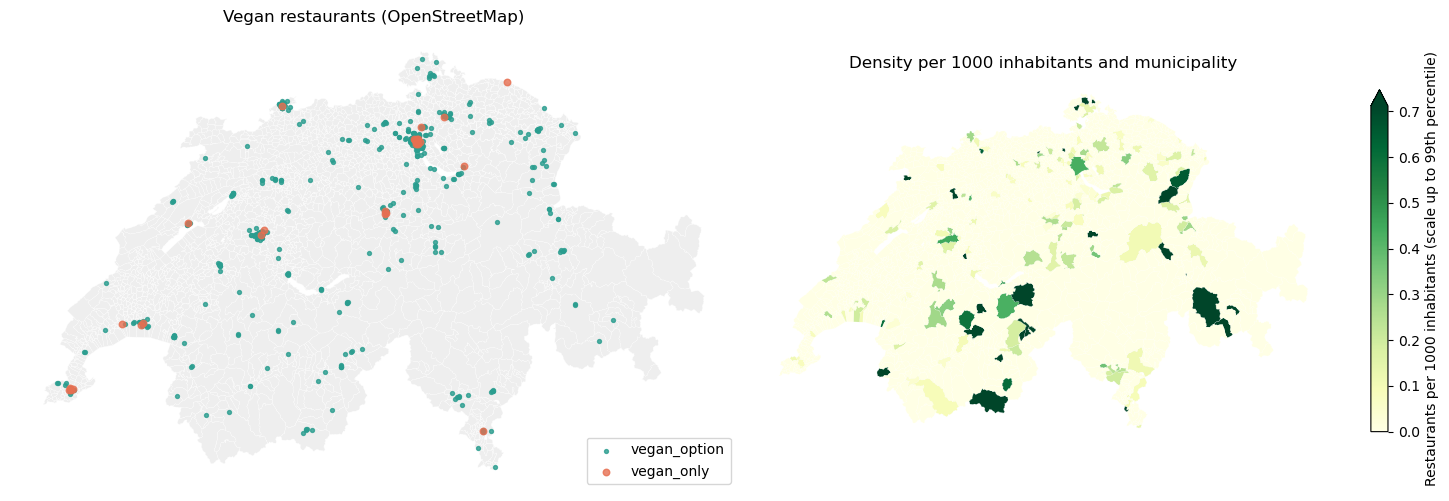

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

muni_stat.plot(ax=axes[0], color='#eeeeee', edgecolor='white', linewidth=0.2)
colors = {'vegan_option': '#2a9d8f', 'vegan_only': '#e76f51'}
for cat, color in colors.items():
    sub = joined[joined['vegan_category'] == cat]
    sub.plot(ax=axes[0], color=color, markersize=8 if cat == 'vegan_option' else 22, label=cat, alpha=0.8)
axes[0].set_title('Vegan restaurants (OpenStreetMap)')
axes[0].legend(loc='lower right')
axes[0].set_axis_off()

vmax = muni_stat['density_per_1000'].quantile(0.99)
muni_stat.plot(ax=axes[1], column='density_per_1000', cmap='YlGn', vmin=0, vmax=vmax, edgecolor='white', linewidth=0.1,
               legend=True, legend_kwds={'label': 'Restaurants per 1000 inhabitants (scale up to 99th percentile)', 'shrink': 0.6})
axes[1].set_title('Density per 1000 inhabitants and municipality')
axes[1].set_axis_off()

plt.tight_layout()
plt.savefig('../figures/map_density_overview.png', dpi=150)
plt.show()

## 7. Save results (municipality map and integration log)

In [10]:
# A simplified geometry (50 m) is enough for maps; the spatial join above uses the exact boundaries.
muni_map = muni_stat.copy()
muni_map['geometry'] = muni_map.geometry.simplify(50, preserve_topology=True)
muni_map.to_file('../data/processed/municipalities_2026.gpkg', layer='municipalities', driver='GPKG')

log_df = pd.DataFrame(integration_log)
log_df.to_csv('../data/processed/integration_log.csv', index=False, encoding='utf-8')
with sqlite3.connect(DB_PATH) as conn:
    log_df.to_sql('integration_log', conn, if_exists='replace', index=False)
log_df

,step,description,n_records
0,1,Territories in swissBOUNDARIES3D (raw),2136
1,1,of which municipal territories of Switzerland ...,2110
2,2,Current municipalities in the BFS municipality...,2110
3,2,BFS numbers in boundary file but not in directory,0
4,2,BFS numbers in directory but not in boundary file,0
5,3,Restaurants from OpenStreetMap,712
6,3,Restaurants assigned to a municipality,712
7,3,Restaurants without municipality (e.g. in a la...,0
8,3,"Restaurants assigned twice (check, should be 0)",0
9,4,Municipalities with at least one restaurant,158
